In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split


In [2]:
import torch
import torch.nn as nn

class RNNModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(RNNModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        out, _ = self.rnn(x, h0)
        out = self.relu(out[:, -1, :])  # Consider only the output of the last time step
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        out = self.softmax(out)
        return out


In [3]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [4]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [5]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [6]:
def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix, y_true, y_pred

def plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path):
    plt.figure(figsize=(10, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', annot_kws={"fontsize": 12})  
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(normalized_conf_matrix, annot=True, cmap='Blues', annot_kws={"fontsize": 12})
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Normalized Confusion Matrix.png'))
    plt.show()


In [7]:
def train_model():
    
    global dwt_level,model,mfcc
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    dwt_level = int(input("Enter dwt level:  "))
    mfcc=int(input("Enter Number of MFCC coefficients : "))
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_features(x,dwt_level))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    X = np.expand_dims(X, -1)
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = 1
    hidden_size = 256
    num_layers = 1

        
    print(f"Input size for wavelet level {dwt_level} = {input_size}")
    # Initialize model

    model = RNNModel(input_size, hidden_size, num_layers, num_classes)
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    print("Training with DWT level:", dwt_level)
    print(
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    num_epochs =int(input("Enter no. of epochs "))
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
        
    mfcc_path="N_MFCC"+str(mfcc)
    mfcc_dir=os.path.join(dataset_dir,mfcc_path)
    
    dwt_level_path = "level "+str(dwt_level)+" wavelet"
    dwt_level_dir = os.path.join(mfcc_dir,dwt_level_path)
    if not os.path.exists(dwt_level_dir):
        os.makedirs(dwt_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(dwt_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validation Precision', 'Validation Recall', 'Validation F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))

    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix, _, _ = generate_confusion_matrix(model, val_loader, device)
    normalized_conf_matrix = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
    plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path)
     
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [8]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [9]:
def extract_features(filename,dwt_level):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    coeffs = pywt.wavedec(y, 'db1', level=dwt_level) # Adjust wavelet and decomposition level as needed
    mfcc_features = []
    for coeff in coeffs:
        mfcc_coeff = np.mean(librosa.feature.mfcc(y=coeff.astype(float), sr=sr, n_mfcc=mfcc).T, axis=0)
        mfcc_features.extend(mfcc_coeff)
    return np.array(mfcc_features)


In [10]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# Tess
# dwt 1
# mfcc 40

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 7
Input size for wavelet level 1 = 1
Training with DWT level: 1
Hidden Size : 256
Model Name: RNNModel

X Shape : (2800, 80, 1)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7810, Training Accuracy: 0.5661, Training Precision:0.6185,Training Recall:0.5661,Training F1-Score:0.5519
Validation Loss: 1.6189, Validation Accuracy: 0.5661, Validation Precision:0.6292,Validation Recall:0.5661,Validation F1-Score:0.5504
Epoch [2/500],
Training Loss: 1.5572, Training Accuracy: 0.6192, Training Precision:0.6616,Training Recall:0.6192,Training F1-Score:0.6182
Validation Loss: 1.5741, Validation Accuracy: 0.6125, Validation Precision:0.6488,Validation Recall:0.6125,Validation F1-Score:0.6101
Epoch [3/500],
Training Loss: 1.4721, Training Accuracy: 0.7295, Training Precision:0.7517,Training Recall:0.7295,Training F1-Score:0.7246
Validation Los

Epoch [30/500],
Training Loss: 1.2405, Training Accuracy: 0.9388, Training Precision:0.9406,Training Recall:0.9388,Training F1-Score:0.9390
Validation Loss: 1.2746, Validation Accuracy: 0.8929, Validation Precision:0.8964,Validation Recall:0.8929,Validation F1-Score:0.8930
Epoch [31/500],
Training Loss: 1.2292, Training Accuracy: 0.9504, Training Precision:0.9536,Training Recall:0.9504,Training F1-Score:0.9510
Validation Loss: 1.2644, Validation Accuracy: 0.9000, Validation Precision:0.9053,Validation Recall:0.9000,Validation F1-Score:0.9008
Epoch [32/500],
Training Loss: 1.2381, Training Accuracy: 0.9402, Training Precision:0.9435,Training Recall:0.9402,Training F1-Score:0.9408
Validation Loss: 1.2624, Validation Accuracy: 0.9000, Validation Precision:0.9038,Validation Recall:0.9000,Validation F1-Score:0.8999
Epoch [33/500],
Training Loss: 1.2243, Training Accuracy: 0.9607, Training Precision:0.9614,Training Recall:0.9607,Training F1-Score:0.9608
Validation Loss: 1.2433, Validation Ac

Epoch [60/500],
Training Loss: 1.2023, Training Accuracy: 0.9487, Training Precision:0.9504,Training Recall:0.9487,Training F1-Score:0.9489
Validation Loss: 1.2703, Validation Accuracy: 0.8929, Validation Precision:0.8985,Validation Recall:0.8929,Validation F1-Score:0.8931
Epoch [61/500],
Training Loss: 1.2134, Training Accuracy: 0.9688, Training Precision:0.9688,Training Recall:0.9688,Training F1-Score:0.9686
Validation Loss: 1.2465, Validation Accuracy: 0.9232, Validation Precision:0.9232,Validation Recall:0.9232,Validation F1-Score:0.9225
Epoch [62/500],
Training Loss: 1.2096, Training Accuracy: 0.9576, Training Precision:0.9590,Training Recall:0.9576,Training F1-Score:0.9575
Validation Loss: 1.2533, Validation Accuracy: 0.9125, Validation Precision:0.9160,Validation Recall:0.9125,Validation F1-Score:0.9131
Epoch [63/500],
Training Loss: 1.2062, Training Accuracy: 0.9339, Training Precision:0.9397,Training Recall:0.9339,Training F1-Score:0.9333
Validation Loss: 1.2588, Validation Ac

Epoch [90/500],
Training Loss: 1.1963, Training Accuracy: 0.9723, Training Precision:0.9731,Training Recall:0.9723,Training F1-Score:0.9724
Validation Loss: 1.2353, Validation Accuracy: 0.9304, Validation Precision:0.9350,Validation Recall:0.9304,Validation F1-Score:0.9304
Epoch [91/500],
Training Loss: 1.2045, Training Accuracy: 0.9603, Training Precision:0.9628,Training Recall:0.9603,Training F1-Score:0.9604
Validation Loss: 1.2285, Validation Accuracy: 0.9393, Validation Precision:0.9413,Validation Recall:0.9393,Validation F1-Score:0.9392
Epoch [92/500],
Training Loss: 1.2017, Training Accuracy: 0.9750, Training Precision:0.9751,Training Recall:0.9750,Training F1-Score:0.9750
Validation Loss: 1.2361, Validation Accuracy: 0.9304, Validation Precision:0.9316,Validation Recall:0.9304,Validation F1-Score:0.9303
Epoch [93/500],
Training Loss: 1.2031, Training Accuracy: 0.9616, Training Precision:0.9643,Training Recall:0.9616,Training F1-Score:0.9617
Validation Loss: 1.2590, Validation Ac

Epoch [120/500],
Training Loss: 1.1886, Training Accuracy: 0.9817, Training Precision:0.9819,Training Recall:0.9817,Training F1-Score:0.9816
Validation Loss: 1.2208, Validation Accuracy: 0.9446, Validation Precision:0.9447,Validation Recall:0.9446,Validation F1-Score:0.9446
Epoch [121/500],
Training Loss: 1.1825, Training Accuracy: 0.9812, Training Precision:0.9818,Training Recall:0.9812,Training F1-Score:0.9813
Validation Loss: 1.2206, Validation Accuracy: 0.9446, Validation Precision:0.9487,Validation Recall:0.9446,Validation F1-Score:0.9448
Epoch [122/500],
Training Loss: 1.1832, Training Accuracy: 0.9857, Training Precision:0.9858,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 1.2274, Validation Accuracy: 0.9375, Validation Precision:0.9392,Validation Recall:0.9375,Validation F1-Score:0.9374
Epoch [123/500],
Training Loss: 1.1829, Training Accuracy: 0.9853, Training Precision:0.9853,Training Recall:0.9853,Training F1-Score:0.9852
Validation Loss: 1.2195, Validatio

...

Epoch [360/500],
Training Loss: 1.2409, Training Accuracy: 0.9138, Training Precision:0.9151,Training Recall:0.9138,Training F1-Score:0.9131
Validation Loss: 1.3016, Validation Accuracy: 0.8643, Validation Precision:0.8691,Validation Recall:0.8643,Validation F1-Score:0.8640
Epoch [361/500],
Training Loss: 1.2456, Training Accuracy: 0.9393, Training Precision:0.9396,Training Recall:0.9393,Training F1-Score:0.9393
Validation Loss: 1.2876, Validation Accuracy: 0.8804, Validation Precision:0.8810,Validation Recall:0.8804,Validation F1-Score:0.8799
Epoch [362/500],
Training Loss: 1.2339, Training Accuracy: 0.9299, Training Precision:0.9323,Training Recall:0.9299,Training F1-Score:0.9302
Validation Loss: 1.3013, Validation Accuracy: 0.8643, Validation Precision:0.8786,Validation Recall:0.8643,Validation F1-Score:0.8665
Epoch [363/500],
Training Loss: 1.2275, Training Accuracy: 0.9496, Training Precision:0.9504,Training Recall:0.9496,Training F1-Score:0.9495
Validation Loss: 1.2698, Validatio

Epoch [390/500],
Training Loss: 1.2585, Training Accuracy: 0.8969, Training Precision:0.8983,Training Recall:0.8969,Training F1-Score:0.8957
Validation Loss: 1.3284, Validation Accuracy: 0.8375, Validation Precision:0.8378,Validation Recall:0.8375,Validation F1-Score:0.8353
Epoch [391/500],
Training Loss: 1.2642, Training Accuracy: 0.9134, Training Precision:0.9150,Training Recall:0.9134,Training F1-Score:0.9131
Validation Loss: 1.2898, Validation Accuracy: 0.8750, Validation Precision:0.8779,Validation Recall:0.8750,Validation F1-Score:0.8751
Epoch [392/500],
Training Loss: 1.2730, Training Accuracy: 0.9299, Training Precision:0.9301,Training Recall:0.9299,Training F1-Score:0.9298
Validation Loss: 1.2836, Validation Accuracy: 0.8821, Validation Precision:0.8856,Validation Recall:0.8821,Validation F1-Score:0.8828
Epoch [393/500],
Training Loss: 1.2374, Training Accuracy: 0.9371, Training Precision:0.9366,Training Recall:0.9371,Training F1-Score:0.9362
Validation Loss: 1.2700, Validatio

Epoch [420/500],
Training Loss: 1.2048, Training Accuracy: 0.9607, Training Precision:0.9613,Training Recall:0.9607,Training F1-Score:0.9607
Validation Loss: 1.2484, Validation Accuracy: 0.9196, Validation Precision:0.9230,Validation Recall:0.9196,Validation F1-Score:0.9198
Epoch [421/500],
Training Loss: 1.2017, Training Accuracy: 0.9656, Training Precision:0.9666,Training Recall:0.9656,Training F1-Score:0.9656
Validation Loss: 1.2472, Validation Accuracy: 0.9161, Validation Precision:0.9198,Validation Recall:0.9161,Validation F1-Score:0.9162
Epoch [422/500],
Training Loss: 1.1998, Training Accuracy: 0.9754, Training Precision:0.9758,Training Recall:0.9754,Training F1-Score:0.9755
Validation Loss: 1.2370, Validation Accuracy: 0.9250, Validation Precision:0.9280,Validation Recall:0.9250,Validation F1-Score:0.9253
Epoch [423/500],
Training Loss: 1.1925, Training Accuracy: 0.9777, Training Precision:0.9781,Training Recall:0.9777,Training F1-Score:0.9777
Validation Loss: 1.2463, Validatio

Epoch [450/500],
Training Loss: 1.2107, Training Accuracy: 0.9406, Training Precision:0.9417,Training Recall:0.9406,Training F1-Score:0.9404
Validation Loss: 1.2632, Validation Accuracy: 0.9000, Validation Precision:0.9021,Validation Recall:0.9000,Validation F1-Score:0.8989
Epoch [451/500],
Training Loss: 1.2137, Training Accuracy: 0.9585, Training Precision:0.9590,Training Recall:0.9585,Training F1-Score:0.9583
Validation Loss: 1.2324, Validation Accuracy: 0.9321, Validation Precision:0.9355,Validation Recall:0.9321,Validation F1-Score:0.9326
Epoch [452/500],
Training Loss: 1.2158, Training Accuracy: 0.9540, Training Precision:0.9544,Training Recall:0.9540,Training F1-Score:0.9539
Validation Loss: 1.2519, Validation Accuracy: 0.9125, Validation Precision:0.9141,Validation Recall:0.9125,Validation F1-Score:0.9126
Epoch [453/500],
Training Loss: 1.2132, Training Accuracy: 0.9585, Training Precision:0.9592,Training Recall:0.9585,Training F1-Score:0.9585
Validation Loss: 1.2483, Validatio

Epoch [480/500],
Training Loss: 1.3164, Training Accuracy: 0.8607, Training Precision:0.8661,Training Recall:0.8607,Training F1-Score:0.8589
Validation Loss: 1.3416, Validation Accuracy: 0.8214, Validation Precision:0.8217,Validation Recall:0.8214,Validation F1-Score:0.8199
Epoch [481/500],
Training Loss: 1.2948, Training Accuracy: 0.8955, Training Precision:0.8967,Training Recall:0.8955,Training F1-Score:0.8954
Validation Loss: 1.3177, Validation Accuracy: 0.8464, Validation Precision:0.8477,Validation Recall:0.8464,Validation F1-Score:0.8464
Epoch [482/500],
Training Loss: 1.2804, Training Accuracy: 0.9013, Training Precision:0.9048,Training Recall:0.9013,Training F1-Score:0.9018
Validation Loss: 1.3186, Validation Accuracy: 0.8429, Validation Precision:0.8490,Validation Recall:0.8429,Validation F1-Score:0.8436
Epoch [483/500],
Training Loss: 1.2760, Training Accuracy: 0.8893, Training Precision:0.8902,Training Recall:0.8893,Training F1-Score:0.8890
Validation Loss: 1.3204, Validatio

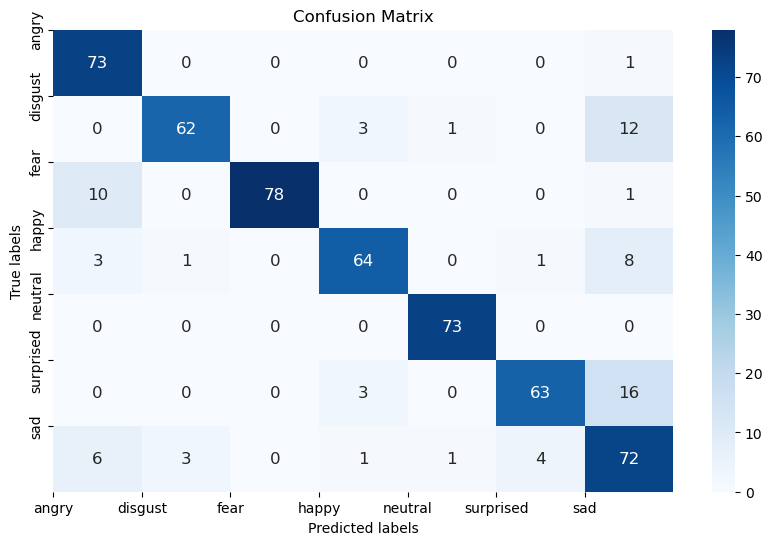

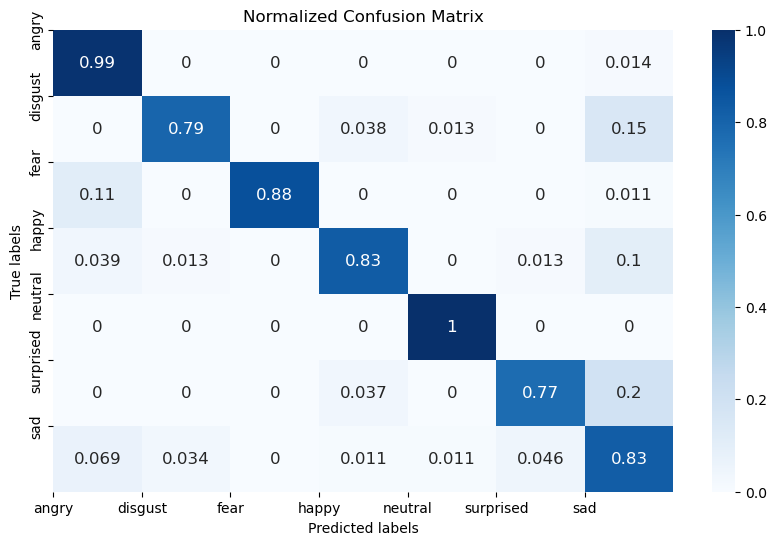

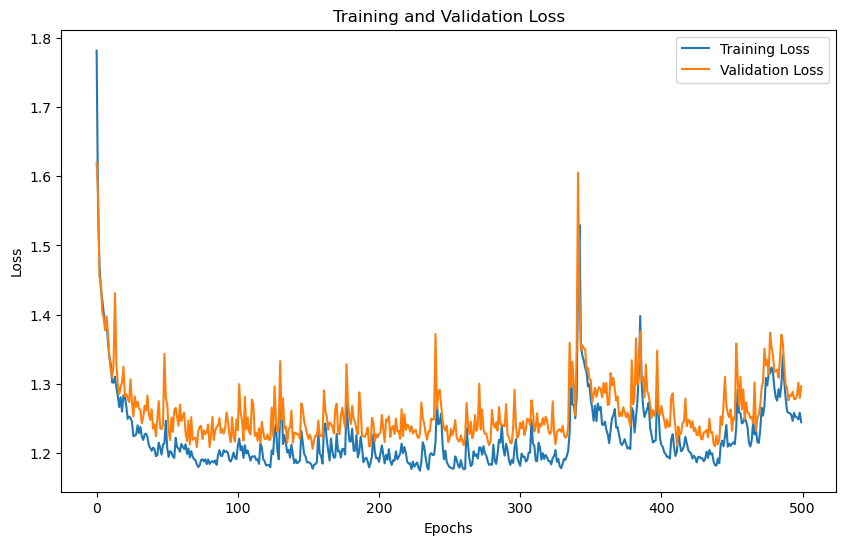

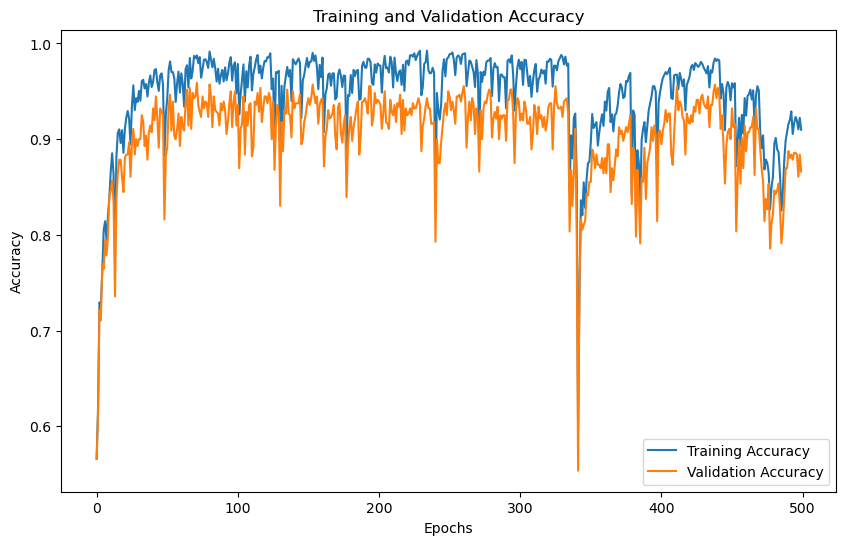

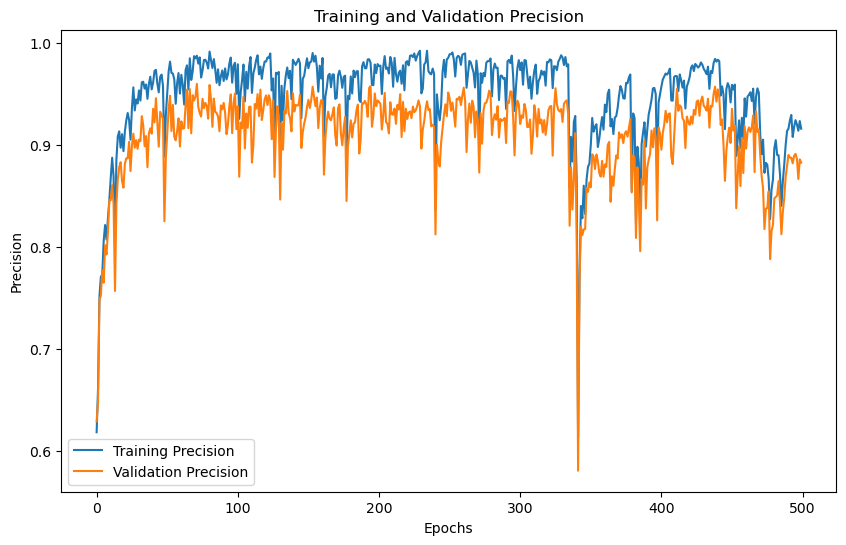

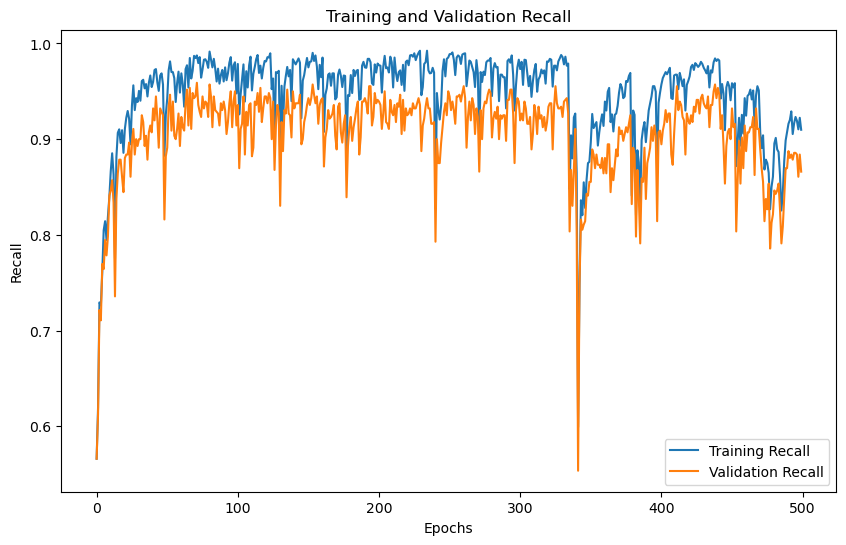

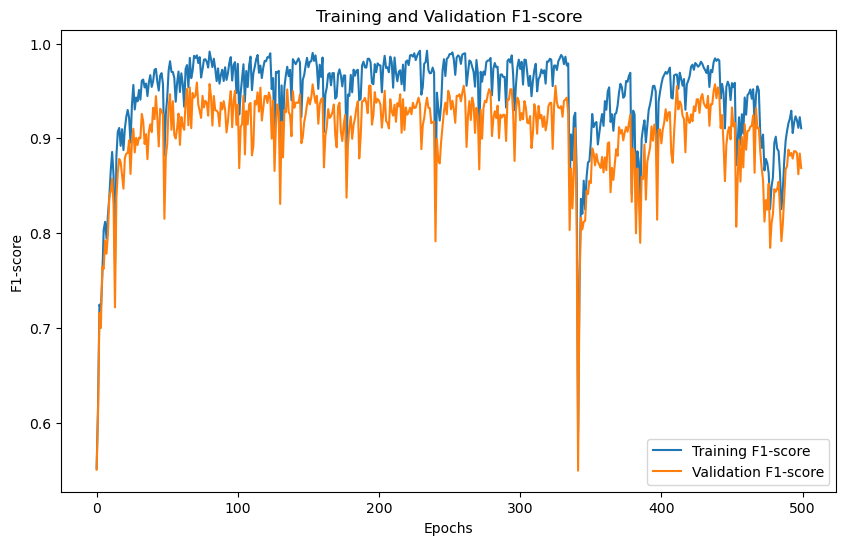

'Model Training and Evaluation Successfully completed'

In [11]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 1 = 1
Training with DWT level: 1
Hidden Size : 256
Model Name: RNNModel

X Shape : (480, 80, 1)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7847, Training Accuracy: 0.2630, Training Precision:0.1238,Training Recall:0.2630,Training F1-Score:0.1446
Validation Loss: 1.7544, Validation Accuracy: 0.2917, Validation Precision:0.1855,Validation Recall:0.2917,Validation F1-Score:0.1753
Epoch [2/500],
Training Loss: 1.7649, Training Accuracy: 0.2370, Training Precision:0.2016,Training Recall:0.2370,Training F1-Score:0.1012
Validation Loss: 1.6903, Validation Accuracy: 0.3542, Validation Precision:0.3739,Validation Recall:0.3542,Validation F1-Score:0.2079
Epoch [3/500],
Training Loss: 1.7502, Training Accuracy: 0.2734, Training Precision:0.1305,Training Recall:0.2734,Training F1-Score:0.1767
Validation Loss

Epoch [30/500],
Training Loss: 1.6183, Training Accuracy: 0.4036, Training Precision:0.2611,Training Recall:0.4036,Training F1-Score:0.3141
Validation Loss: 1.5798, Validation Accuracy: 0.4583, Validation Precision:0.3594,Validation Recall:0.4583,Validation F1-Score:0.3992
Epoch [31/500],
Training Loss: 1.6101, Training Accuracy: 0.4245, Training Precision:0.2947,Training Recall:0.4245,Training F1-Score:0.3252
Validation Loss: 1.5749, Validation Accuracy: 0.4479, Validation Precision:0.2983,Validation Recall:0.4479,Validation F1-Score:0.3547
Epoch [32/500],
Training Loss: 1.6193, Training Accuracy: 0.3542, Training Precision:0.2689,Training Recall:0.3542,Training F1-Score:0.2911
Validation Loss: 1.6191, Validation Accuracy: 0.4167, Validation Precision:0.3770,Validation Recall:0.4167,Validation F1-Score:0.3807
Epoch [33/500],
Training Loss: 1.6343, Training Accuracy: 0.3958, Training Precision:0.2967,Training Recall:0.3958,Training F1-Score:0.3142
Validation Loss: 1.5788, Validation Ac

Epoch [60/500],
Training Loss: 1.5550, Training Accuracy: 0.4922, Training Precision:0.4210,Training Recall:0.4922,Training F1-Score:0.4396
Validation Loss: 1.5548, Validation Accuracy: 0.4583, Validation Precision:0.4068,Validation Recall:0.4583,Validation F1-Score:0.4289
Epoch [61/500],
Training Loss: 1.5528, Training Accuracy: 0.4531, Training Precision:0.3917,Training Recall:0.4531,Training F1-Score:0.3948
Validation Loss: 1.5894, Validation Accuracy: 0.4271, Validation Precision:0.3546,Validation Recall:0.4271,Validation F1-Score:0.3710
Epoch [62/500],
Training Loss: 1.5854, Training Accuracy: 0.3802, Training Precision:0.3362,Training Recall:0.3802,Training F1-Score:0.3481
Validation Loss: 1.6711, Validation Accuracy: 0.3438, Validation Precision:0.3739,Validation Recall:0.3438,Validation F1-Score:0.3521
Epoch [63/500],
Training Loss: 1.6020, Training Accuracy: 0.4427, Training Precision:0.3629,Training Recall:0.4427,Training F1-Score:0.3682
Validation Loss: 1.5978, Validation Ac

Epoch [90/500],
Training Loss: 1.4874, Training Accuracy: 0.5729, Training Precision:0.5068,Training Recall:0.5729,Training F1-Score:0.5169
Validation Loss: 1.5559, Validation Accuracy: 0.4688, Validation Precision:0.4431,Validation Recall:0.4688,Validation F1-Score:0.4430
Epoch [91/500],
Training Loss: 1.4883, Training Accuracy: 0.5729, Training Precision:0.5027,Training Recall:0.5729,Training F1-Score:0.5189
Validation Loss: 1.5761, Validation Accuracy: 0.4479, Validation Precision:0.4230,Validation Recall:0.4479,Validation F1-Score:0.4260
Epoch [92/500],
Training Loss: 1.5372, Training Accuracy: 0.4688, Training Precision:0.3879,Training Recall:0.4688,Training F1-Score:0.4001
Validation Loss: 1.6026, Validation Accuracy: 0.4375, Validation Precision:0.3260,Validation Recall:0.4375,Validation F1-Score:0.3621
Epoch [93/500],
Training Loss: 1.5696, Training Accuracy: 0.3568, Training Precision:0.2978,Training Recall:0.3568,Training F1-Score:0.3136
Validation Loss: 1.6385, Validation Ac

Epoch [120/500],
Training Loss: 1.5459, Training Accuracy: 0.5208, Training Precision:0.4554,Training Recall:0.5208,Training F1-Score:0.4626
Validation Loss: 1.5622, Validation Accuracy: 0.4688, Validation Precision:0.3996,Validation Recall:0.4688,Validation F1-Score:0.4248
Epoch [121/500],
Training Loss: 1.5459, Training Accuracy: 0.4870, Training Precision:0.4081,Training Recall:0.4870,Training F1-Score:0.4276
Validation Loss: 1.5642, Validation Accuracy: 0.4792, Validation Precision:0.4066,Validation Recall:0.4792,Validation F1-Score:0.4202
Epoch [122/500],
Training Loss: 1.5882, Training Accuracy: 0.4766, Training Precision:0.4076,Training Recall:0.4766,Training F1-Score:0.4162
Validation Loss: 1.5578, Validation Accuracy: 0.4792, Validation Precision:0.4206,Validation Recall:0.4792,Validation F1-Score:0.4195
Epoch [123/500],
Training Loss: 1.5975, Training Accuracy: 0.4531, Training Precision:0.3609,Training Recall:0.4531,Training F1-Score:0.3848
Validation Loss: 1.5789, Validatio

...

Epoch [360/500],
Training Loss: 1.6826, Training Accuracy: 0.3646, Training Precision:0.3504,Training Recall:0.3646,Training F1-Score:0.3016
Validation Loss: 1.7462, Validation Accuracy: 0.2396, Validation Precision:0.1879,Validation Recall:0.2396,Validation F1-Score:0.1955
Epoch [361/500],
Training Loss: 1.6847, Training Accuracy: 0.3854, Training Precision:0.4073,Training Recall:0.3854,Training F1-Score:0.3354
Validation Loss: 1.7006, Validation Accuracy: 0.3021, Validation Precision:0.2003,Validation Recall:0.3021,Validation F1-Score:0.2392
Epoch [362/500],
Training Loss: 1.6632, Training Accuracy: 0.3776, Training Precision:0.3402,Training Recall:0.3776,Training F1-Score:0.3328
Validation Loss: 1.7517, Validation Accuracy: 0.2292, Validation Precision:0.1787,Validation Recall:0.2292,Validation F1-Score:0.1838
Epoch [363/500],
Training Loss: 1.6693, Training Accuracy: 0.3594, Training Precision:0.3468,Training Recall:0.3594,Training F1-Score:0.3007
Validation Loss: 1.7343, Validatio

Epoch [390/500],
Training Loss: 1.7072, Training Accuracy: 0.2734, Training Precision:0.2414,Training Recall:0.2734,Training F1-Score:0.2011
Validation Loss: 1.7490, Validation Accuracy: 0.2917, Validation Precision:0.1993,Validation Recall:0.2917,Validation F1-Score:0.2306
Epoch [391/500],
Training Loss: 1.7864, Training Accuracy: 0.2682, Training Precision:0.1718,Training Recall:0.2682,Training F1-Score:0.1948
Validation Loss: 1.7522, Validation Accuracy: 0.2812, Validation Precision:0.1941,Validation Recall:0.2812,Validation F1-Score:0.2251
Epoch [392/500],
Training Loss: 1.7839, Training Accuracy: 0.2578, Training Precision:0.1701,Training Recall:0.2578,Training F1-Score:0.1835
Validation Loss: 1.7053, Validation Accuracy: 0.3229, Validation Precision:0.2715,Validation Recall:0.3229,Validation F1-Score:0.2479
Epoch [393/500],
Training Loss: 1.7774, Training Accuracy: 0.2552, Training Precision:0.1613,Training Recall:0.2552,Training F1-Score:0.1842
Validation Loss: 1.7200, Validatio

Epoch [420/500],
Training Loss: 1.6669, Training Accuracy: 0.3750, Training Precision:0.1912,Training Recall:0.3750,Training F1-Score:0.2497
Validation Loss: 1.5749, Validation Accuracy: 0.4688, Validation Precision:0.3050,Validation Recall:0.4688,Validation F1-Score:0.3629
Epoch [421/500],
Training Loss: 1.6658, Training Accuracy: 0.3776, Training Precision:0.1940,Training Recall:0.3776,Training F1-Score:0.2524
Validation Loss: 1.5745, Validation Accuracy: 0.4688, Validation Precision:0.3050,Validation Recall:0.4688,Validation F1-Score:0.3629
Epoch [422/500],
Training Loss: 1.6595, Training Accuracy: 0.3854, Training Precision:0.1945,Training Recall:0.3854,Training F1-Score:0.2556
Validation Loss: 1.5736, Validation Accuracy: 0.4688, Validation Precision:0.3050,Validation Recall:0.4688,Validation F1-Score:0.3629
Epoch [423/500],
Training Loss: 1.6508, Training Accuracy: 0.4010, Training Precision:0.2013,Training Recall:0.4010,Training F1-Score:0.2659
Validation Loss: 1.5629, Validatio

Epoch [450/500],
Training Loss: 1.5928, Training Accuracy: 0.4531, Training Precision:0.3856,Training Recall:0.4531,Training F1-Score:0.3333
Validation Loss: 1.5683, Validation Accuracy: 0.4792, Validation Precision:0.3205,Validation Recall:0.4792,Validation F1-Score:0.3777
Epoch [451/500],
Training Loss: 1.5925, Training Accuracy: 0.4531, Training Precision:0.3862,Training Recall:0.4531,Training F1-Score:0.3336
Validation Loss: 1.5625, Validation Accuracy: 0.4896, Validation Precision:0.3215,Validation Recall:0.4896,Validation F1-Score:0.3819
Epoch [452/500],
Training Loss: 1.5924, Training Accuracy: 0.4531, Training Precision:0.3735,Training Recall:0.4531,Training F1-Score:0.3338
Validation Loss: 1.5703, Validation Accuracy: 0.4688, Validation Precision:0.3217,Validation Recall:0.4688,Validation F1-Score:0.3734
Epoch [453/500],
Training Loss: 1.5915, Training Accuracy: 0.4531, Training Precision:0.3867,Training Recall:0.4531,Training F1-Score:0.3340
Validation Loss: 1.5669, Validatio

Epoch [480/500],
Training Loss: 1.6198, Training Accuracy: 0.4271, Training Precision:0.3158,Training Recall:0.4271,Training F1-Score:0.3162
Validation Loss: 1.5554, Validation Accuracy: 0.4896, Validation Precision:0.3742,Validation Recall:0.4896,Validation F1-Score:0.4112
Epoch [481/500],
Training Loss: 1.6069, Training Accuracy: 0.4479, Training Precision:0.3143,Training Recall:0.4479,Training F1-Score:0.3355
Validation Loss: 1.5737, Validation Accuracy: 0.4792, Validation Precision:0.3623,Validation Recall:0.4792,Validation F1-Score:0.4037
Epoch [482/500],
Training Loss: 1.6047, Training Accuracy: 0.4427, Training Precision:0.3455,Training Recall:0.4427,Training F1-Score:0.3256
Validation Loss: 1.5512, Validation Accuracy: 0.4792, Validation Precision:0.3185,Validation Recall:0.4792,Validation F1-Score:0.3785
Epoch [483/500],
Training Loss: 1.5982, Training Accuracy: 0.4453, Training Precision:0.3713,Training Recall:0.4453,Training F1-Score:0.3220
Validation Loss: 1.5289, Validatio

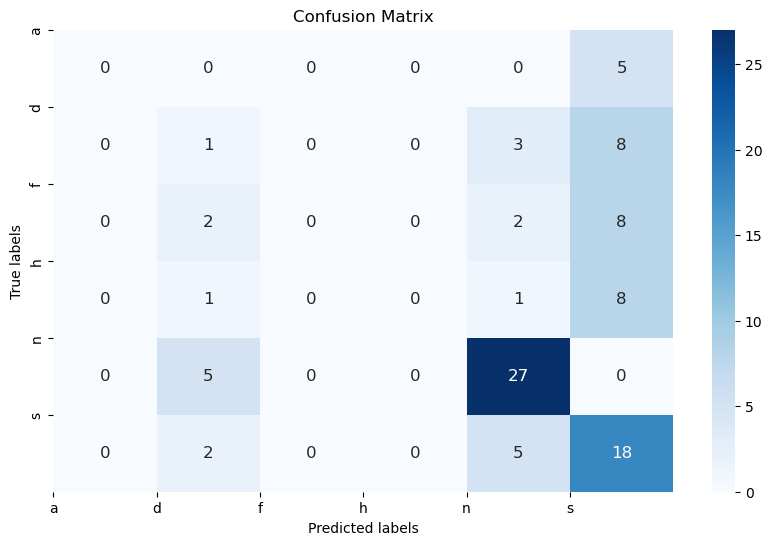

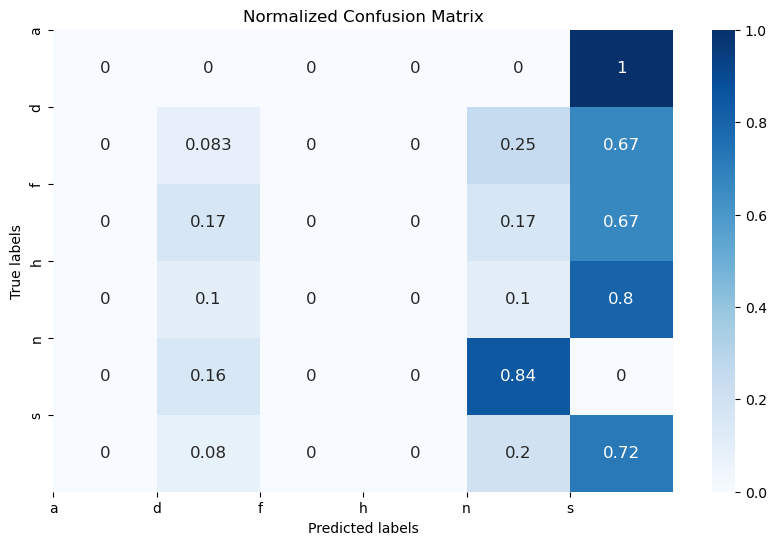

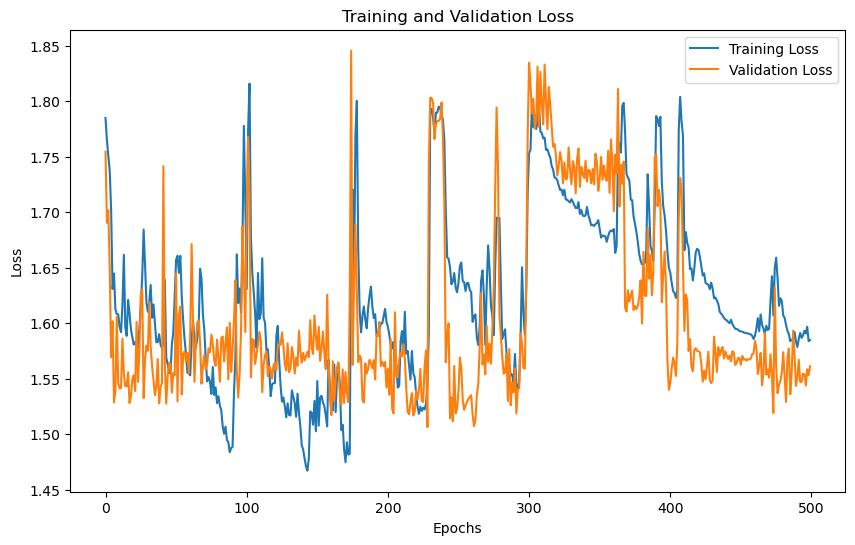

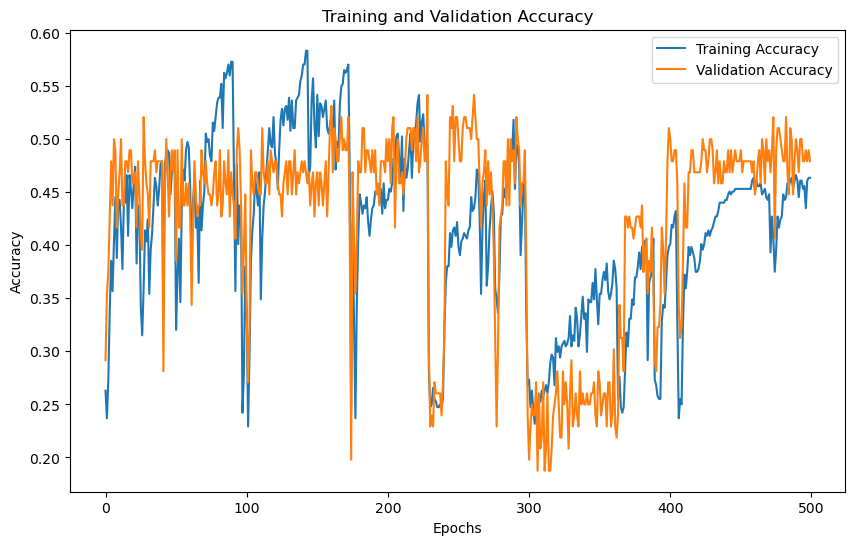

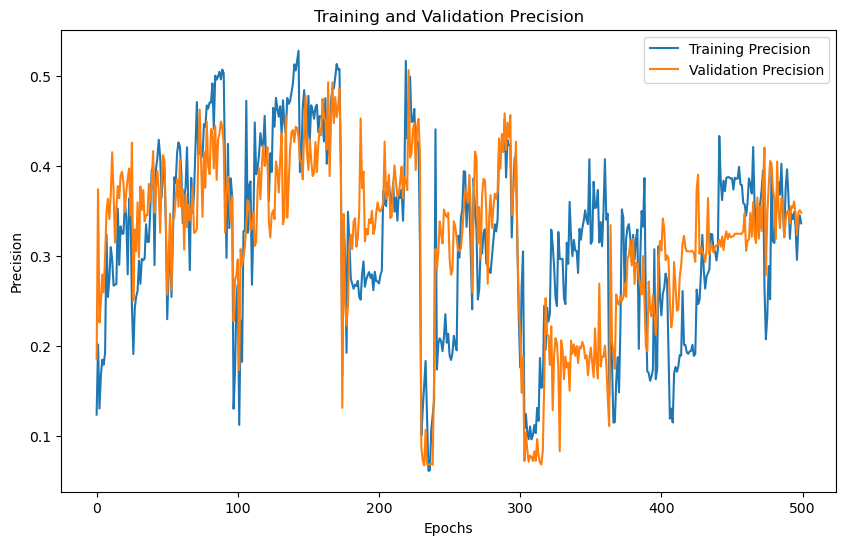

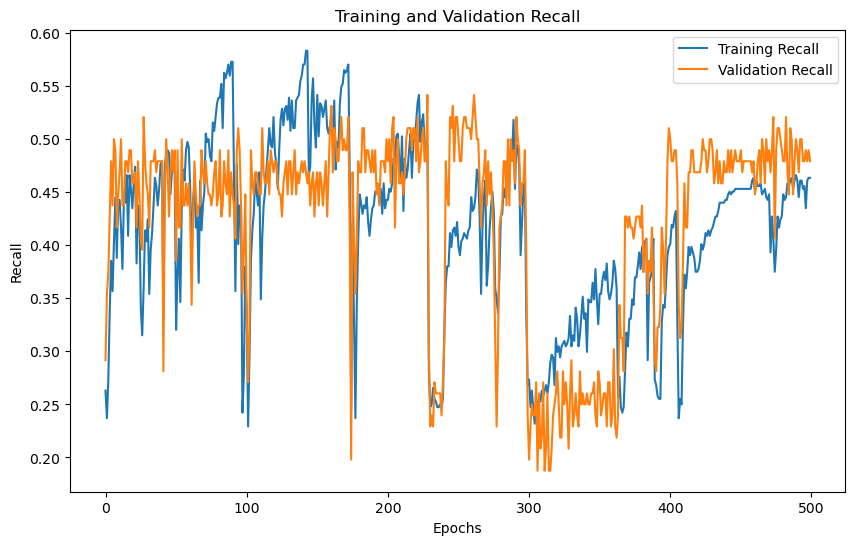

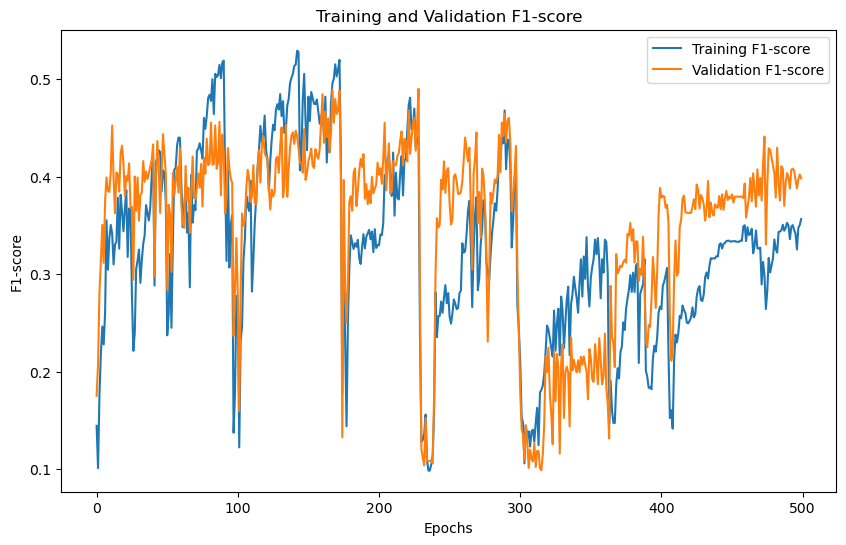

'Model Training and Evaluation Successfully completed'

In [12]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 8
Input size for wavelet level 1 = 1
Training with DWT level: 1
Hidden Size : 256
Model Name: RNNModel

X Shape : (1440, 80, 1)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0689, Training Accuracy: 0.1988, Training Precision:0.0585,Training Recall:0.1988,Training F1-Score:0.0881
Validation Loss: 2.0340, Validation Accuracy: 0.2118, Validation Precision:0.0653,Validation Recall:0.2118,Validation F1-Score:0.0965
Epoch [2/500],
Training Loss: 2.0652, Training Accuracy: 0.1345, Training Precision:0.0621,Training Recall:0.1345,Training F1-Score:0.0558
Validation Loss: 2.0926, Validation Accuracy: 0.1319, Validation Precision:0.0338,Validation Recall:0.1319,Validation F1-Score:0.0538
Epoch [3/500],
Training Loss: 2.0829, Training Accuracy: 0.1050, Training Precision:0.0889,Training Recall:0.1050,Training F1-Score:0.0760
Validation 

Epoch [30/500],
Training Loss: 2.0735, Training Accuracy: 0.1076, Training Precision:0.0502,Training Recall:0.1076,Training F1-Score:0.0521
Validation Loss: 2.0856, Validation Accuracy: 0.0729, Validation Precision:0.0191,Validation Recall:0.0729,Validation F1-Score:0.0303
Epoch [31/500],
Training Loss: 2.0731, Training Accuracy: 0.1424, Training Precision:0.0655,Training Recall:0.1424,Training F1-Score:0.0772
Validation Loss: 2.0747, Validation Accuracy: 0.1215, Validation Precision:0.0352,Validation Recall:0.1215,Validation F1-Score:0.0526
Epoch [32/500],
Training Loss: 2.0697, Training Accuracy: 0.1128, Training Precision:0.0714,Training Recall:0.1128,Training F1-Score:0.0784
Validation Loss: 2.0732, Validation Accuracy: 0.1215, Validation Precision:0.1106,Validation Recall:0.1215,Validation F1-Score:0.1047
Epoch [33/500],
Training Loss: 2.0705, Training Accuracy: 0.1424, Training Precision:0.0647,Training Recall:0.1424,Training F1-Score:0.0504
Validation Loss: 2.0869, Validation Ac

Epoch [60/500],
Training Loss: 2.0689, Training Accuracy: 0.1667, Training Precision:0.0842,Training Recall:0.1667,Training F1-Score:0.0990
Validation Loss: 2.0689, Validation Accuracy: 0.1736, Validation Precision:0.0949,Validation Recall:0.1736,Validation F1-Score:0.1053
Epoch [61/500],
Training Loss: 2.0703, Training Accuracy: 0.1727, Training Precision:0.0911,Training Recall:0.1727,Training F1-Score:0.1069
Validation Loss: 2.0660, Validation Accuracy: 0.1736, Validation Precision:0.0793,Validation Recall:0.1736,Validation F1-Score:0.1032
Epoch [62/500],
Training Loss: 2.0686, Training Accuracy: 0.1424, Training Precision:0.0526,Training Recall:0.1424,Training F1-Score:0.0463
Validation Loss: 2.0810, Validation Accuracy: 0.1181, Validation Precision:0.0806,Validation Recall:0.1181,Validation F1-Score:0.0352
Epoch [63/500],
Training Loss: 2.0743, Training Accuracy: 0.1415, Training Precision:0.0445,Training Recall:0.1415,Training F1-Score:0.0577
Validation Loss: 2.0825, Validation Ac

Epoch [90/500],
Training Loss: 2.0560, Training Accuracy: 0.1788, Training Precision:0.0971,Training Recall:0.1788,Training F1-Score:0.0910
Validation Loss: 2.0673, Validation Accuracy: 0.1632, Validation Precision:0.0452,Validation Recall:0.1632,Validation F1-Score:0.0703
Epoch [91/500],
Training Loss: 2.0556, Training Accuracy: 0.1788, Training Precision:0.0948,Training Recall:0.1788,Training F1-Score:0.0927
Validation Loss: 2.0695, Validation Accuracy: 0.1597, Validation Precision:0.0442,Validation Recall:0.1597,Validation F1-Score:0.0687
Epoch [92/500],
Training Loss: 2.0575, Training Accuracy: 0.1797, Training Precision:0.0961,Training Recall:0.1797,Training F1-Score:0.0883
Validation Loss: 2.0632, Validation Accuracy: 0.1736, Validation Precision:0.0473,Validation Recall:0.1736,Validation F1-Score:0.0743
Epoch [93/500],
Training Loss: 2.0556, Training Accuracy: 0.1771, Training Precision:0.0914,Training Recall:0.1771,Training F1-Score:0.0900
Validation Loss: 2.0689, Validation Ac

Epoch [120/500],
Training Loss: 2.0744, Training Accuracy: 0.1406, Training Precision:0.1024,Training Recall:0.1406,Training F1-Score:0.0605
Validation Loss: 2.0628, Validation Accuracy: 0.1736, Validation Precision:0.1571,Validation Recall:0.1736,Validation F1-Score:0.0850
Epoch [121/500],
Training Loss: 2.0629, Training Accuracy: 0.1771, Training Precision:0.1363,Training Recall:0.1771,Training F1-Score:0.1288
Validation Loss: 2.0512, Validation Accuracy: 0.1840, Validation Precision:0.1309,Validation Recall:0.1840,Validation F1-Score:0.1348
Epoch [122/500],
Training Loss: 2.0515, Training Accuracy: 0.2170, Training Precision:0.1342,Training Recall:0.2170,Training F1-Score:0.1379
Validation Loss: 2.0421, Validation Accuracy: 0.1806, Validation Precision:0.1300,Validation Recall:0.1806,Validation F1-Score:0.1111
Epoch [123/500],
Training Loss: 2.0453, Training Accuracy: 0.1832, Training Precision:0.2352,Training Recall:0.1832,Training F1-Score:0.1223
Validation Loss: 2.0831, Validatio

...

Epoch [360/500],
Training Loss: 2.0345, Training Accuracy: 0.2040, Training Precision:0.3194,Training Recall:0.2040,Training F1-Score:0.1427
Validation Loss: 2.0521, Validation Accuracy: 0.1875, Validation Precision:0.1462,Validation Recall:0.1875,Validation F1-Score:0.1136
Epoch [361/500],
Training Loss: 2.0419, Training Accuracy: 0.1970, Training Precision:0.1569,Training Recall:0.1970,Training F1-Score:0.1419
Validation Loss: 2.0703, Validation Accuracy: 0.1701, Validation Precision:0.1185,Validation Recall:0.1701,Validation F1-Score:0.1207
Epoch [362/500],
Training Loss: 2.0387, Training Accuracy: 0.1988, Training Precision:0.1957,Training Recall:0.1988,Training F1-Score:0.1381
Validation Loss: 2.0568, Validation Accuracy: 0.1910, Validation Precision:0.1372,Validation Recall:0.1910,Validation F1-Score:0.1182
Epoch [363/500],
Training Loss: 2.0337, Training Accuracy: 0.2031, Training Precision:0.2709,Training Recall:0.2031,Training F1-Score:0.1478
Validation Loss: 2.0535, Validatio

Epoch [390/500],
Training Loss: 2.0392, Training Accuracy: 0.1918, Training Precision:0.3047,Training Recall:0.1918,Training F1-Score:0.1210
Validation Loss: 2.0543, Validation Accuracy: 0.1771, Validation Precision:0.0937,Validation Recall:0.1771,Validation F1-Score:0.0915
Epoch [391/500],
Training Loss: 2.0350, Training Accuracy: 0.2057, Training Precision:0.1754,Training Recall:0.2057,Training F1-Score:0.1555
Validation Loss: 2.0598, Validation Accuracy: 0.1736, Validation Precision:0.1041,Validation Recall:0.1736,Validation F1-Score:0.1203
Epoch [392/500],
Training Loss: 2.0327, Training Accuracy: 0.2109, Training Precision:0.3489,Training Recall:0.2109,Training F1-Score:0.1544
Validation Loss: 2.0502, Validation Accuracy: 0.1910, Validation Precision:0.1981,Validation Recall:0.1910,Validation F1-Score:0.1224
Epoch [393/500],
Training Loss: 2.0299, Training Accuracy: 0.2144, Training Precision:0.3254,Training Recall:0.2144,Training F1-Score:0.1568
Validation Loss: 2.0467, Validatio

Epoch [420/500],
Training Loss: 2.0305, Training Accuracy: 0.2118, Training Precision:0.3558,Training Recall:0.2118,Training F1-Score:0.1519
Validation Loss: 2.0526, Validation Accuracy: 0.1875, Validation Precision:0.1617,Validation Recall:0.1875,Validation F1-Score:0.1179
Epoch [421/500],
Training Loss: 2.0290, Training Accuracy: 0.2092, Training Precision:0.3202,Training Recall:0.2092,Training F1-Score:0.1548
Validation Loss: 2.0524, Validation Accuracy: 0.1979, Validation Precision:0.1503,Validation Recall:0.1979,Validation F1-Score:0.1345
Epoch [422/500],
Training Loss: 2.0293, Training Accuracy: 0.2118, Training Precision:0.3294,Training Recall:0.2118,Training F1-Score:0.1661
Validation Loss: 2.0513, Validation Accuracy: 0.2049, Validation Precision:0.1636,Validation Recall:0.2049,Validation F1-Score:0.1467
Epoch [423/500],
Training Loss: 2.0282, Training Accuracy: 0.2118, Training Precision:0.4415,Training Recall:0.2118,Training F1-Score:0.1738
Validation Loss: 2.0520, Validatio

Epoch [450/500],
Training Loss: 2.0283, Training Accuracy: 0.2179, Training Precision:0.3372,Training Recall:0.2179,Training F1-Score:0.1647
Validation Loss: 2.0510, Validation Accuracy: 0.1979, Validation Precision:0.1934,Validation Recall:0.1979,Validation F1-Score:0.1394
Epoch [451/500],
Training Loss: 2.0294, Training Accuracy: 0.2170, Training Precision:0.3294,Training Recall:0.2170,Training F1-Score:0.1637
Validation Loss: 2.0509, Validation Accuracy: 0.2014, Validation Precision:0.1927,Validation Recall:0.2014,Validation F1-Score:0.1428
Epoch [452/500],
Training Loss: 2.0304, Training Accuracy: 0.2083, Training Precision:0.2881,Training Recall:0.2083,Training F1-Score:0.1592
Validation Loss: 2.0491, Validation Accuracy: 0.2118, Validation Precision:0.2571,Validation Recall:0.2118,Validation F1-Score:0.1563
Epoch [453/500],
Training Loss: 2.0286, Training Accuracy: 0.2170, Training Precision:0.3051,Training Recall:0.2170,Training F1-Score:0.1586
Validation Loss: 2.0501, Validatio

Epoch [480/500],
Training Loss: 2.0294, Training Accuracy: 0.2170, Training Precision:0.3321,Training Recall:0.2170,Training F1-Score:0.1639
Validation Loss: 2.0557, Validation Accuracy: 0.1840, Validation Precision:0.1157,Validation Recall:0.1840,Validation F1-Score:0.1156
Epoch [481/500],
Training Loss: 2.0273, Training Accuracy: 0.2144, Training Precision:0.2956,Training Recall:0.2144,Training F1-Score:0.1591
Validation Loss: 2.0539, Validation Accuracy: 0.2014, Validation Precision:0.1403,Validation Recall:0.2014,Validation F1-Score:0.1396
Epoch [482/500],
Training Loss: 2.0277, Training Accuracy: 0.2127, Training Precision:0.3240,Training Recall:0.2127,Training F1-Score:0.1556
Validation Loss: 2.0572, Validation Accuracy: 0.1910, Validation Precision:0.1420,Validation Recall:0.1910,Validation F1-Score:0.1198
Epoch [483/500],
Training Loss: 2.0300, Training Accuracy: 0.2179, Training Precision:0.3032,Training Recall:0.2179,Training F1-Score:0.1687
Validation Loss: 2.0521, Validatio

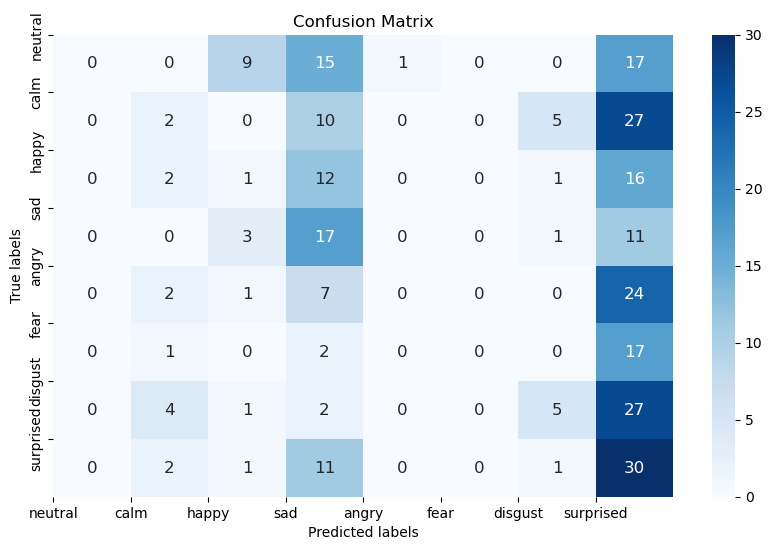

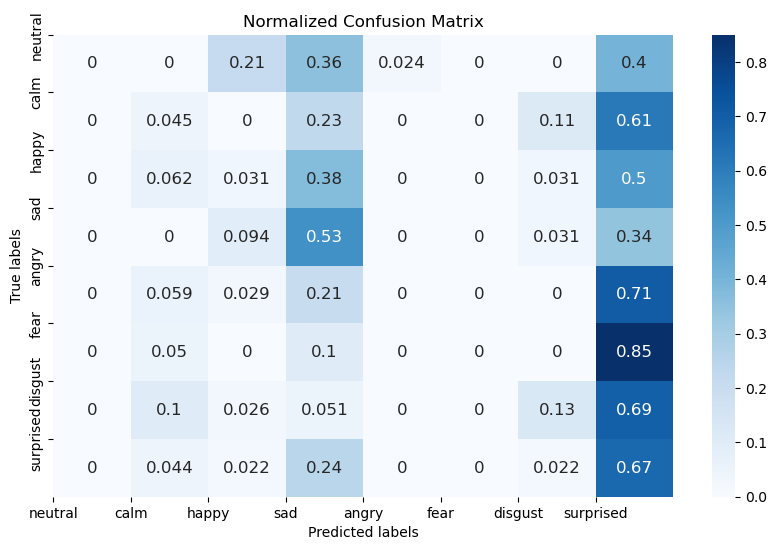

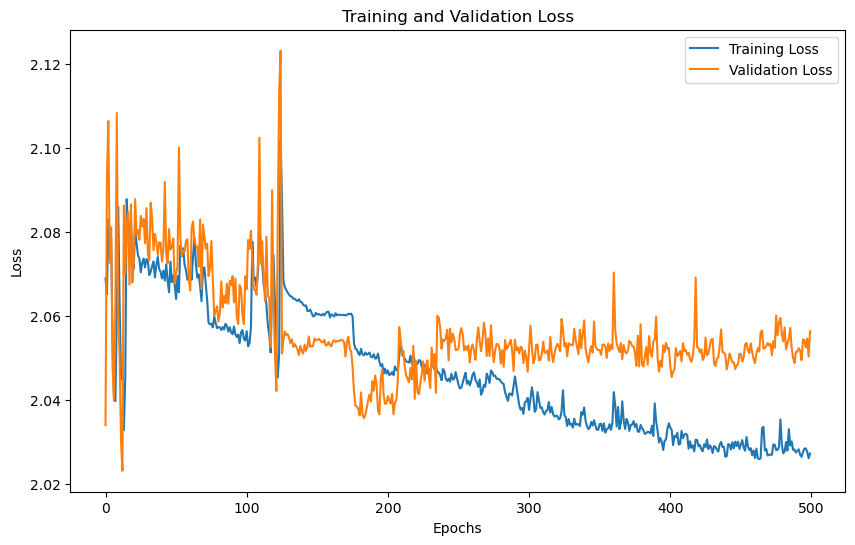

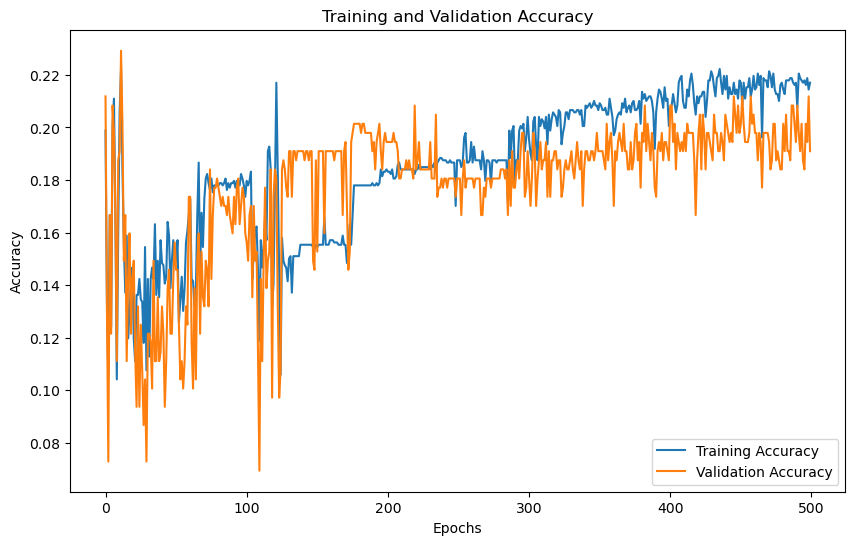

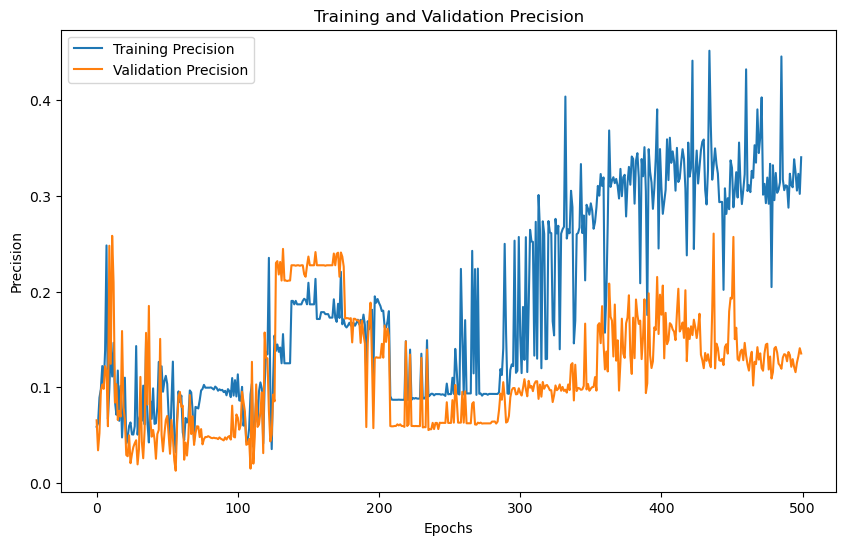

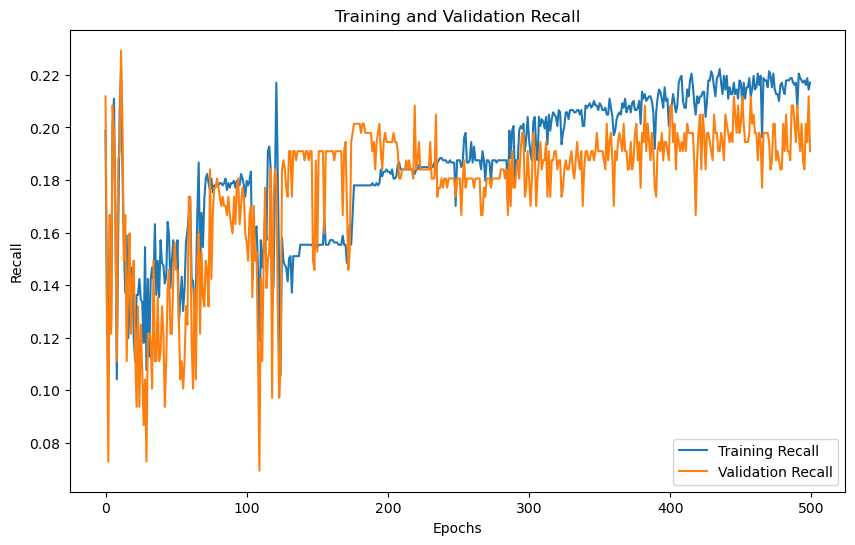

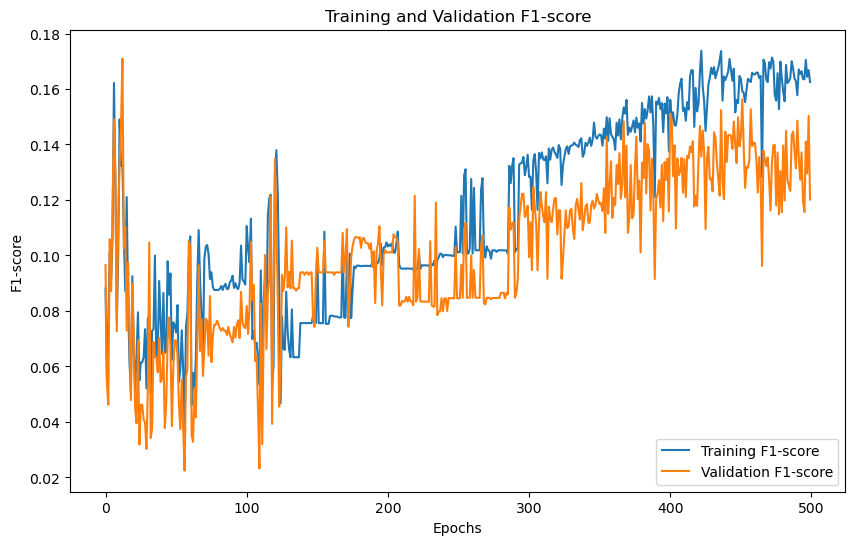

'Model Training and Evaluation Successfully completed'

In [14]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 1 = 1
Training with DWT level: 1
Hidden Size : 256
Model Name: RNNModel

X Shape : (7442, 80, 1)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7882, Training Accuracy: 0.1497, Training Precision:0.0646,Training Recall:0.1497,Training F1-Score:0.0605
Validation Loss: 1.8299, Validation Accuracy: 0.1390, Validation Precision:0.0560,Validation Recall:0.1390,Validation F1-Score:0.0523
Epoch [2/500],
Training Loss: 1.7855, Training Accuracy: 0.1514, Training Precision:0.0514,Training Recall:0.1514,Training F1-Score:0.0757
Validation Loss: 1.8240, Validation Accuracy: 0.1370, Validation Precision:0.0452,Validation Recall:0.1370,Validation F1-Score:0.0664
Epoch [3/500],
Training Loss: 1.7377, Training Accuracy: 0.3180, Training Precision:0.1893,Training Recall:0.3180,Training F1-Score:0.2008
Validation Lo

Epoch [30/500],
Training Loss: 1.7894, Training Accuracy: 0.1821, Training Precision:0.0932,Training Recall:0.1821,Training F1-Score:0.0892
Validation Loss: 1.7899, Validation Accuracy: 0.1632, Validation Precision:0.0948,Validation Recall:0.1632,Validation F1-Score:0.0802
Epoch [31/500],
Training Loss: 1.7886, Training Accuracy: 0.1730, Training Precision:0.0518,Training Recall:0.1730,Training F1-Score:0.0595
Validation Loss: 1.7937, Validation Accuracy: 0.1592, Validation Precision:0.0526,Validation Recall:0.1592,Validation F1-Score:0.0546
Epoch [32/500],
Training Loss: 1.7879, Training Accuracy: 0.1863, Training Precision:0.0881,Training Recall:0.1863,Training F1-Score:0.0909
Validation Loss: 1.7890, Validation Accuracy: 0.1666, Validation Precision:0.0613,Validation Recall:0.1666,Validation F1-Score:0.0784
Epoch [33/500],
Training Loss: 1.7866, Training Accuracy: 0.1913, Training Precision:0.1076,Training Recall:0.1913,Training F1-Score:0.1120
Validation Loss: 1.7870, Validation Ac

Epoch [60/500],
Training Loss: 1.7790, Training Accuracy: 0.2122, Training Precision:0.1061,Training Recall:0.2122,Training F1-Score:0.1361
Validation Loss: 1.7803, Validation Accuracy: 0.2035, Validation Precision:0.0991,Validation Recall:0.2035,Validation F1-Score:0.1292
Epoch [61/500],
Training Loss: 1.7805, Training Accuracy: 0.2051, Training Precision:0.1042,Training Recall:0.2051,Training F1-Score:0.1239
Validation Loss: 1.7833, Validation Accuracy: 0.1988, Validation Precision:0.0958,Validation Recall:0.1988,Validation F1-Score:0.1155
Epoch [62/500],
Training Loss: 1.7820, Training Accuracy: 0.2135, Training Precision:0.1067,Training Recall:0.2135,Training F1-Score:0.1330
Validation Loss: 1.7820, Validation Accuracy: 0.2035, Validation Precision:0.0931,Validation Recall:0.2035,Validation F1-Score:0.1197
Epoch [63/500],
Training Loss: 1.7806, Training Accuracy: 0.2179, Training Precision:0.2797,Training Recall:0.2179,Training F1-Score:0.1385
Validation Loss: 1.7761, Validation Ac

Epoch [90/500],
Training Loss: 1.7828, Training Accuracy: 0.1996, Training Precision:0.1271,Training Recall:0.1996,Training F1-Score:0.1111
Validation Loss: 1.7843, Validation Accuracy: 0.2035, Validation Precision:0.1375,Validation Recall:0.2035,Validation F1-Score:0.1129
Epoch [91/500],
Training Loss: 1.7830, Training Accuracy: 0.2054, Training Precision:0.1029,Training Recall:0.2054,Training F1-Score:0.1255
Validation Loss: 1.7829, Validation Accuracy: 0.1968, Validation Precision:0.0918,Validation Recall:0.1968,Validation F1-Score:0.1162
Epoch [92/500],
Training Loss: 1.7860, Training Accuracy: 0.1831, Training Precision:0.1074,Training Recall:0.1831,Training F1-Score:0.0863
Validation Loss: 1.7870, Validation Accuracy: 0.1860, Validation Precision:0.0863,Validation Recall:0.1860,Validation F1-Score:0.0814
Epoch [93/500],
Training Loss: 1.7831, Training Accuracy: 0.2039, Training Precision:0.0993,Training Recall:0.2039,Training F1-Score:0.1201
Validation Loss: 1.7826, Validation Ac

Epoch [120/500],
Training Loss: 1.7794, Training Accuracy: 0.2036, Training Precision:0.1303,Training Recall:0.2036,Training F1-Score:0.1442
Validation Loss: 1.7845, Validation Accuracy: 0.1914, Validation Precision:0.1278,Validation Recall:0.1914,Validation F1-Score:0.1319
Epoch [121/500],
Training Loss: 1.7811, Training Accuracy: 0.1846, Training Precision:0.1245,Training Recall:0.1846,Training F1-Score:0.1182
Validation Loss: 1.7954, Validation Accuracy: 0.1746, Validation Precision:0.1166,Validation Recall:0.1746,Validation F1-Score:0.1136
Epoch [122/500],
Training Loss: 1.8073, Training Accuracy: 0.1693, Training Precision:0.0614,Training Recall:0.1693,Training F1-Score:0.0502
Validation Loss: 1.8034, Validation Accuracy: 0.1739, Validation Precision:0.2084,Validation Recall:0.1739,Validation F1-Score:0.0542
Epoch [123/500],
Training Loss: 1.7905, Training Accuracy: 0.1708, Training Precision:0.0532,Training Recall:0.1708,Training F1-Score:0.0595
Validation Loss: 1.7896, Validatio

...

Epoch [360/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7915, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [361/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7914, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [362/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7914, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [363/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7914, Validatio

Epoch [390/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7915, Validation Accuracy: 0.1605, Validation Precision:0.0258,Validation Recall:0.1605,Validation F1-Score:0.0444
Epoch [391/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7914, Validation Accuracy: 0.1605, Validation Precision:0.0258,Validation Recall:0.1605,Validation F1-Score:0.0444
Epoch [392/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7914, Validation Accuracy: 0.1605, Validation Precision:0.0258,Validation Recall:0.1605,Validation F1-Score:0.0444
Epoch [393/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7913, Validatio

Epoch [420/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7914, Validation Accuracy: 0.1605, Validation Precision:0.0258,Validation Recall:0.1605,Validation F1-Score:0.0444
Epoch [421/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7914, Validation Accuracy: 0.1605, Validation Precision:0.0258,Validation Recall:0.1605,Validation F1-Score:0.0444
Epoch [422/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7916, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [423/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7915, Validatio

Epoch [450/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7916, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [451/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7915, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [452/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7915, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [453/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7914, Validatio

Epoch [480/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7917, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [481/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7916, Validation Accuracy: 0.1605, Validation Precision:0.0258,Validation Recall:0.1605,Validation F1-Score:0.0444
Epoch [482/500],
Training Loss: 1.7900, Training Accuracy: 0.1740, Training Precision:0.0303,Training Recall:0.1740,Training F1-Score:0.0516
Validation Loss: 1.7916, Validation Accuracy: 0.1578, Validation Precision:0.0249,Validation Recall:0.1578,Validation F1-Score:0.0430
Epoch [483/500],
Training Loss: 1.7900, Training Accuracy: 0.1734, Training Precision:0.0301,Training Recall:0.1734,Training F1-Score:0.0512
Validation Loss: 1.7916, Validatio

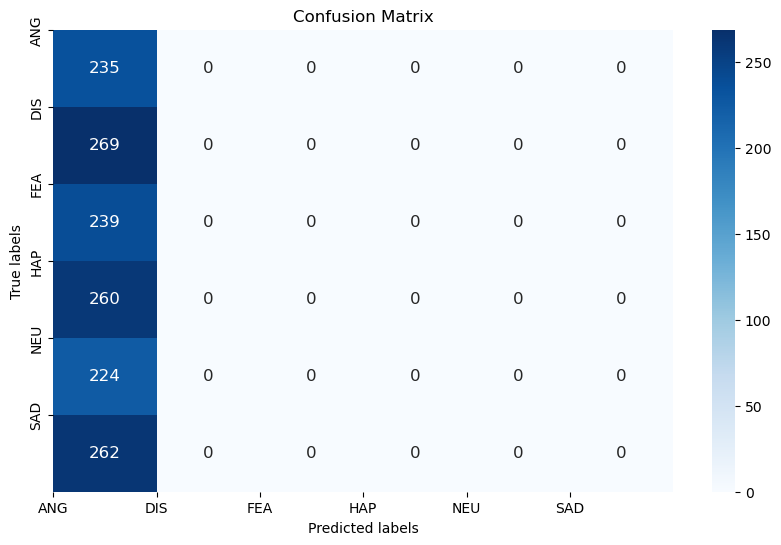

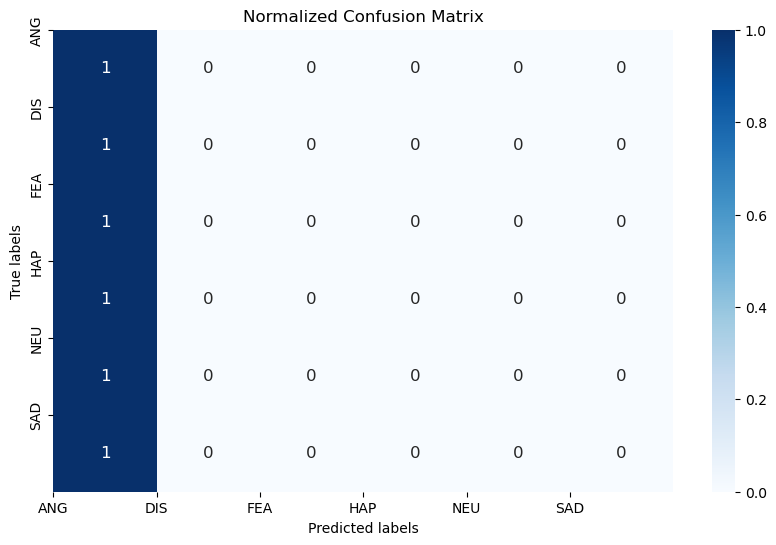

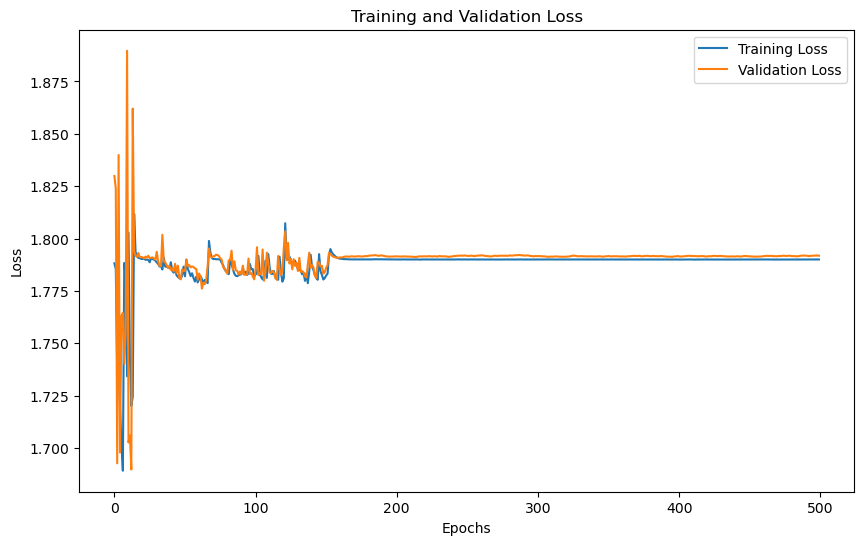

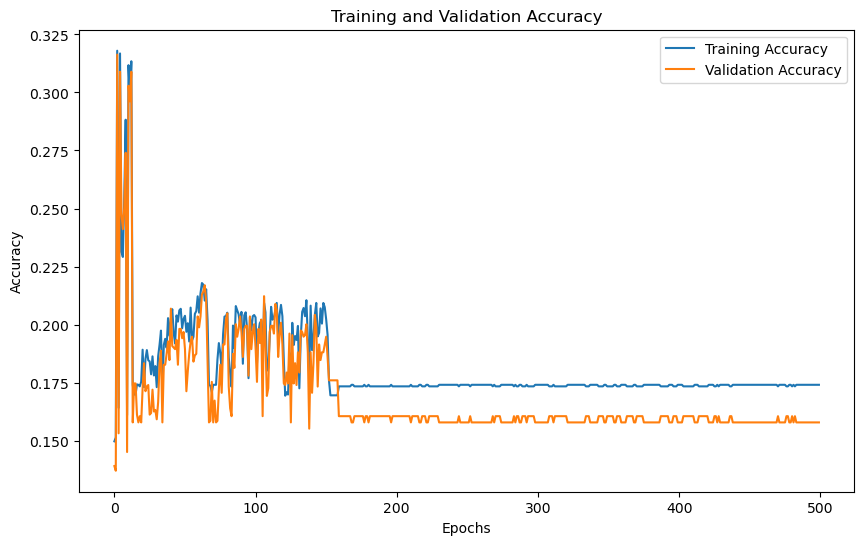

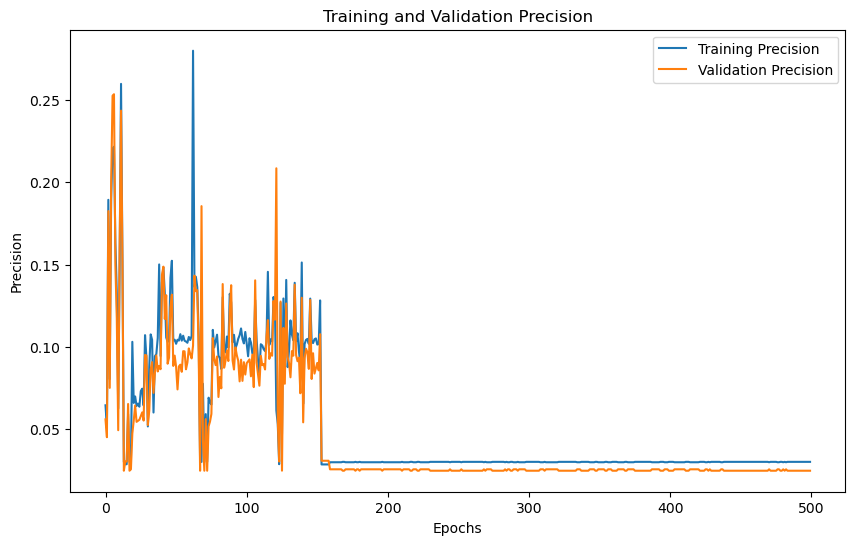

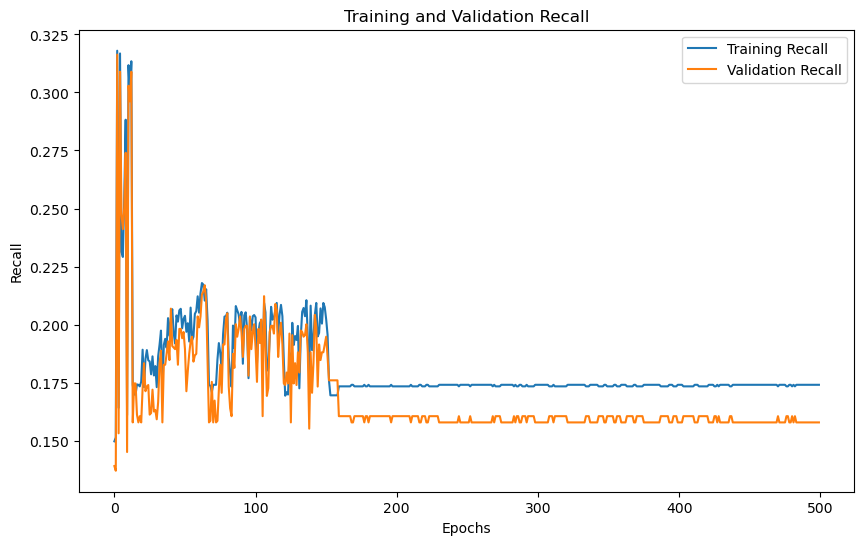

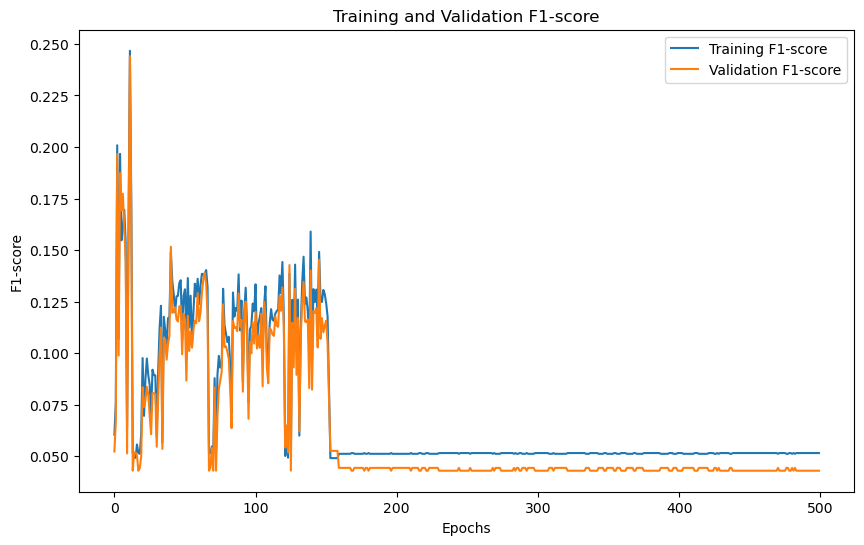

'Model Training and Evaluation Successfully completed'

In [16]:
train_model()